**Study of Multiplication Tables in a Spreadsheet**

**1.   Visual Representation of the First Multiples**

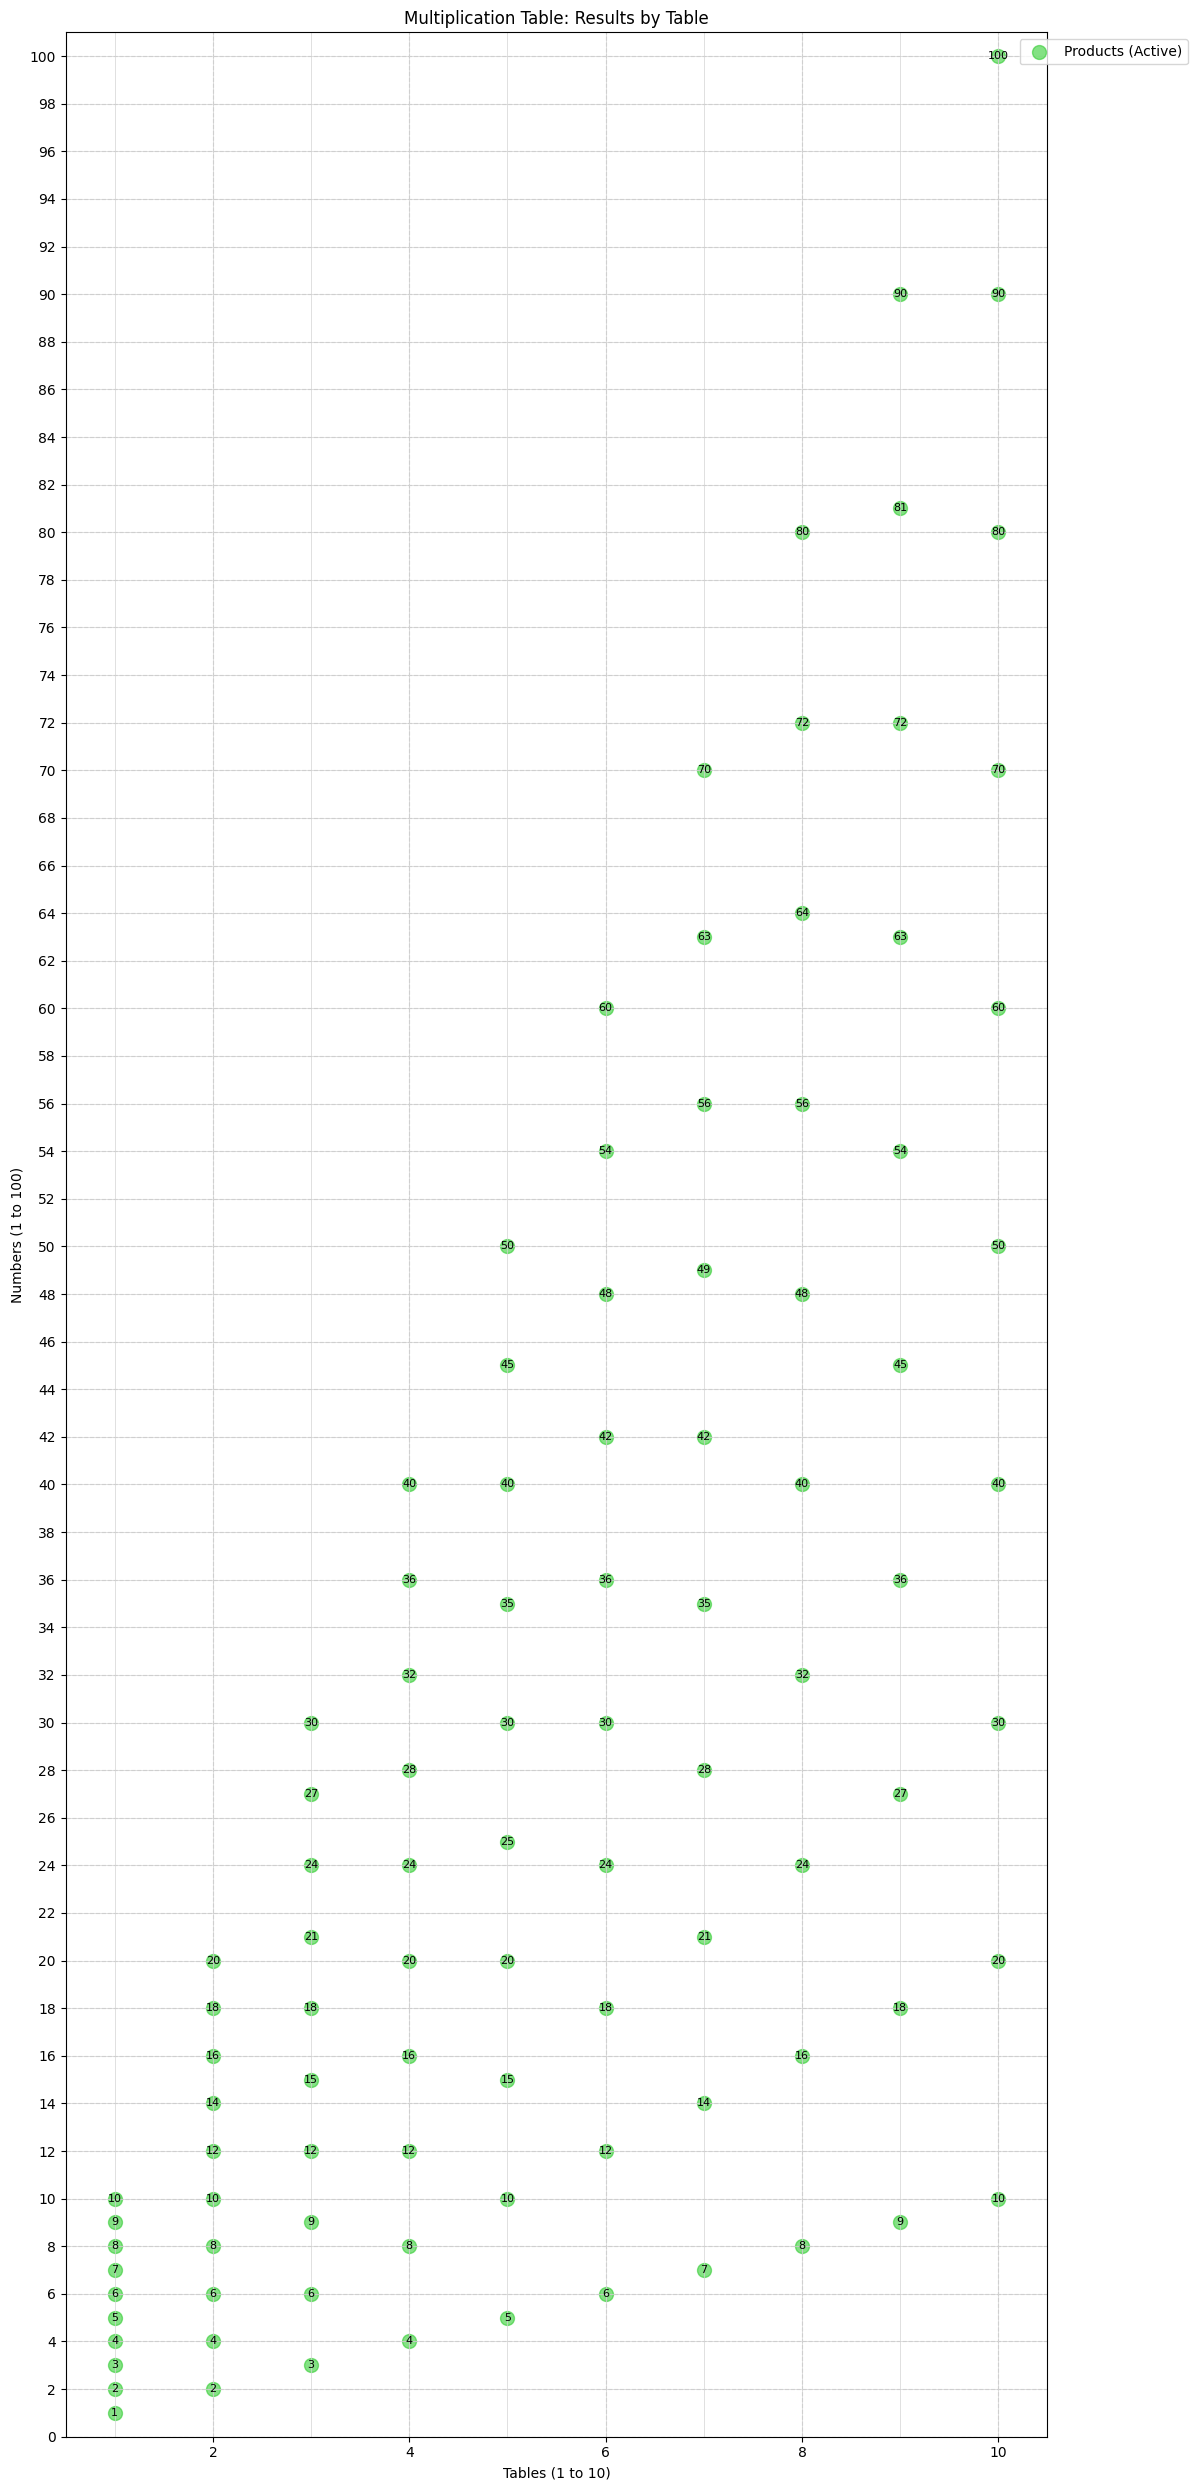

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Configuration and Data ---
# Define our table limits
MAX_TABLE = 10
MAX_RESULT = 100

# Store the coordinates of "active" points (the table products)
active_x = []
active_y = []
active_results = []

# Generate the active points
for table in range(1, MAX_TABLE + 1):
    for multiplier in range(1, MAX_TABLE + 1):
        result = table * multiplier
        if result <= MAX_RESULT:
            active_x.append(table)
            active_y.append(result)
            active_results.append(str(result))

# --- Visualization ---
# Create a large figure for better readability
plt.figure(figsize=(12, 25))

# Plot active points in vivid green
plt.scatter(active_x, active_y, c='limegreen', s=100, alpha=0.6, label='Products (Active)')

# Annotate each point with its result
for i, (xi, yi, res) in enumerate(zip(active_x, active_y, active_results)):
    plt.annotate(res, (xi, yi), textcoords="offset points", xytext=(0, 0), ha='center', va='center', fontsize=8)

# Plot grid lines for the table
for table in range(1, MAX_TABLE + 1):
    plt.vlines(table, 0, MAX_RESULT + 1, colors='lightgray', linestyles='-', linewidth=0.5)
for result in range(0, MAX_RESULT + 1, 2):
    plt.hlines(result, 0.5, MAX_TABLE + 0.5, colors='lightgray', linestyles='-', linewidth=0.5)

# --- Graph Metadata ---
# Define the title and axis labels for clear reading
plt.title('Multiplication Table: Results by Table')
plt.xlabel('Tables (1 to 10)')
plt.ylabel('Numbers (1 to 100)')

# Adjust limits and ticks
plt.xlim(0.5, MAX_TABLE + 0.5)
plt.ylim(0, MAX_RESULT + 1)
plt.yticks(np.arange(0, MAX_RESULT + 1, 2))
plt.grid(True, linestyle='--', alpha=0.7)

# Add a legend and display the graph
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.tight_layout()
plt.show()

**2.   Visual Representation of Multiples beyond 10**

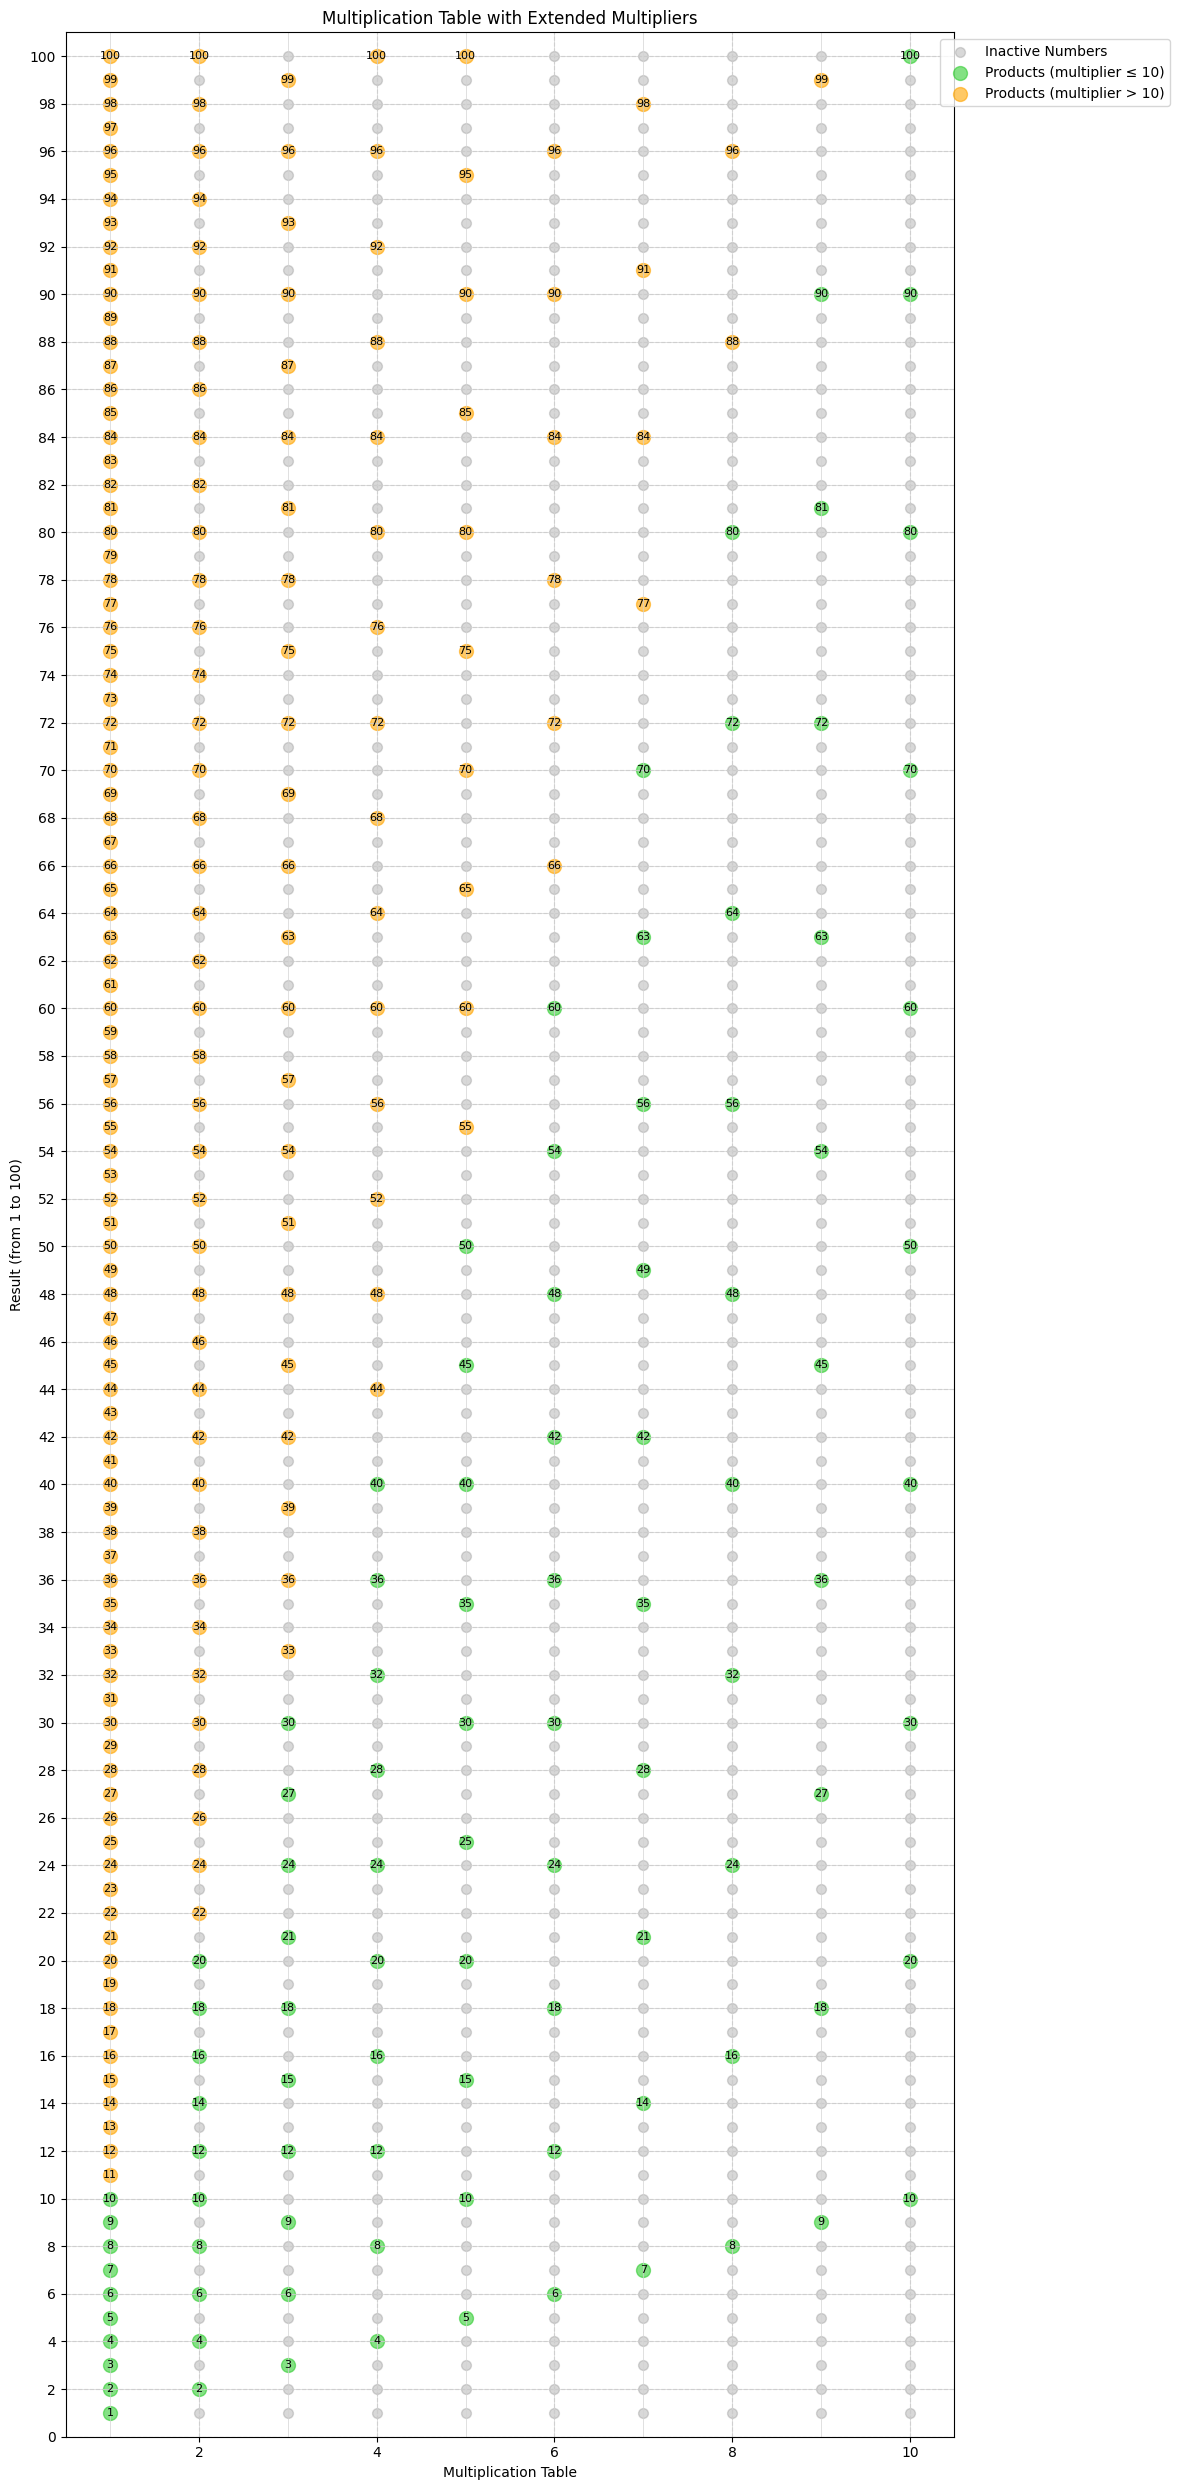

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Configuration and Data ---
# Define our table limits
MAX_TABLE = 10
MAX_RESULT = 100
MAX_MULTIPLIER = 100

# Create a set of active points for quick lookup
active_points_low_set = set()
active_points_high_set = set()

# Store coordinates for plotting
active_x_low, active_y_low = [], []
active_x_high, active_y_high = [], []
active_results_low, active_results_high = [], []

# Generate all active points and separate them by multiplier
for table in range(1, MAX_TABLE + 1):
    for multiplier in range(1, MAX_MULTIPLIER + 1):
        result = table * multiplier
        if result <= MAX_RESULT:
            if multiplier <= 10:
                active_x_low.append(table)
                active_y_low.append(result)
                active_results_low.append(str(result))
                active_points_low_set.add((table, result))
            else:
                active_x_high.append(table)
                active_y_high.append(result)
                active_results_high.append(str(result))
                active_points_high_set.add((table, result))

# --- Visualization ---
plt.figure(figsize=(12, 25))

# Identify inactive points in a single step
all_active_points = active_points_low_set.union(active_points_high_set)
inactive_x, inactive_y = [], []
for table in range(1, MAX_TABLE + 1):
    for num in range(1, MAX_RESULT + 1):
        if (table, num) not in all_active_points:
            inactive_x.append(table)
            inactive_y.append(num)

# Plot inactive points in gray in the background
plt.scatter(inactive_x, inactive_y, c='gray', s=50, alpha=0.3, label='Inactive Numbers')

# Plot active points for multipliers <= 10
plt.scatter(active_x_low, active_y_low, c='limegreen', s=100, alpha=0.6, label='Products (multiplier ≤ 10)')

# Plot active points for multipliers > 10
plt.scatter(active_x_high, active_y_high, c='orange', s=100, alpha=0.6, label='Products (multiplier > 10)')

# Add annotations (results)
for x, y, res in zip(active_x_low + active_x_high, active_y_low + active_y_high, active_results_low + active_results_high):
    plt.annotate(res, (x, y), textcoords="offset points", xytext=(0, 0), ha='center', va='center', fontsize=8)

# Add the grid to simulate a "table"
for table in range(1, MAX_TABLE + 1):
    plt.vlines(table, 0, MAX_RESULT + 1, colors='lightgray', linestyles='-', linewidth=0.5)
for result in range(0, MAX_RESULT + 1, 2):
    plt.hlines(result, 0.5, MAX_TABLE + 0.5, colors='lightgray', linestyles='-', linewidth=0.5)

# --- Graph Metadata ---
plt.title('Multiplication Table with Extended Multipliers')
plt.xlabel('Multiplication Table')
plt.ylabel('Result (from 1 to 100)')
plt.xlim(0.5, MAX_TABLE + 0.5)
plt.ylim(0, MAX_RESULT + 1)
plt.yticks(np.arange(0, MAX_RESULT + 1, 2))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1))
plt.tight_layout()
plt.show()

**3.   Divisor Analysis Model: The Minimalist GCD Algorithm**

In [ ]:
import numpy as np

def find_divisors(number):
    """
    Returns the set of all divisors of a given number.
    """
    divisors = set()
    for i in range(1, int(np.sqrt(number)) + 1):
        if number % i == 0:
            divisors.add(i)
            divisors.add(number // i)
    return divisors

def display_divisors_table(numbers, divisors_lists):
    """
    Displays a text table showing the divisors of several numbers.
    The columns correspond to the unique divisors of all numbers.
    """
    # Combine and sort all unique divisors for the table columns
    all_divisors = set()
    for d_set in divisors_lists:
        all_divisors.update(d_set)
    all_divisors = sorted(list(all_divisors))

    # Prepare the rows for display
    rows = []
    rows.append(["Number"] + [str(d) for d in all_divisors])  # Header row

    for i, number in enumerate(numbers):
        current_divisors = divisors_lists[i]
        data_row = [str(number)] + [" X " if d in current_divisors else "   " for d in all_divisors]
        rows.append(data_row)

    # Determine column widths for aligned display
    widths = [max(len(item) for item in col_items) for col_items in zip(*rows)]

    # Display the table
    border = " | ".join("-" * width for width in widths)

    print(border)
    print(" | ".join(col.ljust(width) for col, width in zip(rows[0], widths)))
    print(border)
    for row in rows[1:]:
        print(" | ".join(col.ljust(width) for col, width in zip(row, widths)))
    print(border)

# --- Program Usage ---
try:
    print("GCD search program for multiple numbers (type '/' to finish input).\n")
    entered_numbers = []
    while True:
        entry = input(f"Please enter number #{len(entered_numbers) + 1}: ")
        if entry == '/':
            if len(entered_numbers) < 2:
                print("Please enter at least two numbers to calculate the GCD.")
                entered_numbers = []
                continue
            break

        value = int(entry)
        if value <= 0:
            print("Please enter a positive integer.")
        else:
            entered_numbers.append(value)

    # 1. Find the divisors for each entered number
    divisors_lists = [find_divisors(number) for number in entered_numbers]

    # 2. Identify common divisors and the GCD
    common_divisors = set.intersection(*divisors_lists)
    gcd = max(common_divisors) if common_divisors else None

    # 3. Display the table and the result
    print("\n--- Divisor Analysis Table ---")
    display_divisors_table(entered_numbers, divisors_lists)

    print("\n--- Final Result ---")
    if gcd is not None:
        print(f"Common divisors: {sorted(list(common_divisors))}")
        print(f"The Greatest Common Divisor (GCD) is: {gcd}")
    else:
        print("No common divisor found other than 1.")

except ValueError:
    print("Invalid input. Please enter only integers or '/'.")

GCD search program for multiple numbers (type '/' to finish input).



**Conclusion**

**Definition :**
The **Great Common DIvisor** is formally defined as the largest integer value that simultaneously divides two or more integers, without leaving a remainder. The innovation of the MHDN-RT lies in the principle of visual correlation:

**Representation of the Common Divisor (CD) :**
The GCD appears in a tabular representation as the maximum value of a column
that intersects multiple rows (the numbers being analyzed).
*Ex: GCD( 12, 18 ) = 6*


**⚠ EMPIRICAL OBSERVATIONS OF THE MODEL**
*   The analysis reveals a limit to the co-occurrences of the **Common Divisors (CD)** in the 1st Cell. It was empirically established that the maximum number of repetitions of a CD is four within the initial analysis range, suggesting a saturation of divisibility in this context. This observation is not seen in the 2nd Cell, where the co-occurences get more than four.
*   An intrinsic property of the model is that certain multiplication columns (tables) contain a subset of the values from smaller tables. This inclusion phenomenon, observed up to a maximum of five values, is a direct illustration of transitive divisibility.



> *The Cardinal of the Reals, is the Order of Division* (J.Roko)
